In [3]:
#import packages
import numpy as np
import pandas as pd
import sklearn as sk
import statsmodels.api as sm
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

In [4]:
#Upload Data
prospect = pd.read_csv("Final Prospect Rankings Data.csv")

#Question 1:

Do FanGraphs' evaluations systematically misvalue players based on demographic factors like age and developmental origins (highschool, college, or international signing), and to what extent do algorithmic "Risk" penalties reflect these differences? How is a player's signing bonus related to their developmental origin and what impact does that have on their evaluation?

**Average WAR vs. FV**

Reasoning: Allows us to see how well FV correlates to WAR as well as calculate the residuals we will eventually compare across different groups.

In [5]:
#Define Formula
formula = "Q('Average WAR') ~ FV"

#Fit model
war_model = smf.ols(formula=formula, data=prospect).fit()

#Print Summary
print(war_model.summary())

                            OLS Regression Results                            
Dep. Variable:       Q('Average WAR')   R-squared:                       0.232
Model:                            OLS   Adj. R-squared:                  0.231
Method:                 Least Squares   F-statistic:                     737.8
Date:                Sat, 14 Nov 2026   Prob (F-statistic):          3.10e-142
Time:                        01:02:38   Log-Likelihood:                -2094.7
No. Observations:                2450   AIC:                             4193.
Df Residuals:                    2448   BIC:                             4205.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.0585      0.085    -24.356      0.0

Results: FV is a statistically significant predictor of Average WAR. 10 Points of FV correlates to about 0.5 WAR/season.

Add Residuals Column

In [6]:
#Adds column to prospect with residuals from war_predicted_by_FV model
prospect["war_residuals"] = war_model.resid

Plot Residuals:

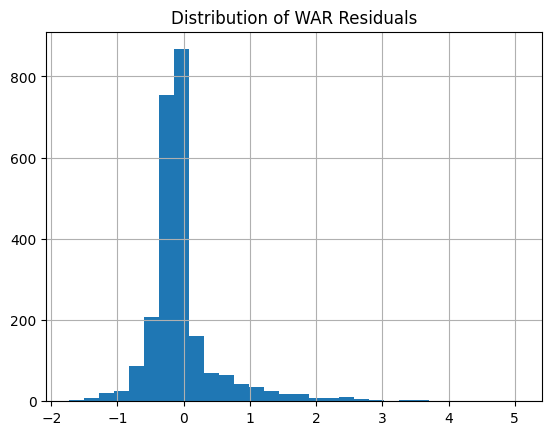

In [7]:
import matplotlib.pyplot as plt

#Create Histogram of WAR residuals to view distribution
prospect["war_residuals"].hist(bins=30)

plt.title('Distribution of WAR Residuals')
plt.show()

Results:
The distribution has a massive spike around zero showing that the FV is an accurate predictor of average war.

The distribution also has a long tail to the right, a small group of players who massively outperform their projections.

The left tail of the distibution drops of sharply with few large residuals. This reflect the harsh reality that  a player who severely underperforms will quickly lose playing time or be sent down, naturally capping how negative their residual can get.

**Model 1 Modeling the Relationship Between Bonus, Background, and Origin**

Reasoning: Allows us to see whether the size of a player's bonus is correlated with their background, age, and position group. This is useful to contextualize bonuses impact in future models.

In [8]:
#Log transforms bonus since it is heavily left skewed
prospect["log_bonus"] = np.log(prospect["Bonus"] + 1)

#Define Fomrula
formula = "log_bonus ~ Background + Age + Pos_Group"

#Fit model
model = smf.ols(formula=formula, data=prospect).fit()

#Print Summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_bonus   R-squared:                       0.257
Model:                            OLS   Adj. R-squared:                  0.253
Method:                 Least Squares   F-statistic:                     68.20
Date:                Sat, 14 Nov 2026   Prob (F-statistic):          5.07e-108
Time:                        01:02:38   Log-Likelihood:                -3310.4
No. Observations:                1788   AIC:                             6641.
Df Residuals:                    1778   BIC:                             6696.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

Results: A players age and background are statistically significant predictors of their bonus (controlling for position group). Age has a negative correlations with bonus, and compared to a standard player coming out of college, highschool players make more while international players make much less. Pitchers are also strongly correlated with the lowest bonus.

**Model 2: Misevaluation based on background, bonus, and age**

Reasoning: Checks if the residuals between a players WAR predicted by their FV and their actual WAR are correlated with thie background, sigining bonus, or age. If they are, indicates bias with FV ratings.

Background and Age vs Residuals

In [9]:
#Define Formula
formula = "war_residuals ~ Background + Age"

#Fit Model
model = smf.ols(formula=formula, data=prospect).fit()

#Print Summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.011
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     8.796
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           8.45e-06
Time:                        01:02:38   Log-Likelihood:                -2081.6
No. Observations:                2450   AIC:                             4171.
Df Residuals:                    2446   BIC:                             4194.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

Results: Age is a statistically significant predictor of a players WAR residual. Older players tend to have higher residuals and outperform their predictions. However, neither of the backgrounds were statsitically significant and it is unclear whether coming from highschool or internationally vs. college has an effect on a players WAR residual. Unfortunately this model was pretty dissapoingting and didn't match our expecations.

Background, bonus, and age, vs Residuals

Reasoning: Check if background is a statistically significant predictor when controlling for siging bonus.

In [10]:
#Define Formula
formula = "war_residuals ~ Background + log_bonus + Age"

#Fit Model
model = smf.ols(formula=formula, data=prospect).fit()

#Print Summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.012
Model:                            OLS   Adj. R-squared:                  0.010
Method:                 Least Squares   F-statistic:                     5.474
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           0.000222
Time:                        01:02:38   Log-Likelihood:                -1609.0
No. Observations:                1788   AIC:                             3228.
Df Residuals:                    1783   BIC:                             3255.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

Results: Once again age is a statistically significant predictor. And once again none of the other predictors were statistically significant. When controlling for background it doesn't seem that bonus has a statistically significant impact on WAR residuals. It is worth noting that International background is marignally significant (p=0.096) suggesting a slight tendency for international signees to underperform their projections compared to college players.

Add interaction term

Reasoning: We suspected that the relationship between a player's signing bonus and their WAR residual varies depending on their developmental background. For example a prospect with a 2 million dollar signing bonus is much more looked at therefore should have better predictions than a prospect signed for 700k. To test this, we added an interaction term (Background * log_bonus).

In [11]:
#Define Formula
formula = "war_residuals ~ Background * log_bonus + Age"

#Fit Model
model = smf.ols(formula=formula, data=prospect).fit()

#Print Summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     6.435
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           1.01e-06
Time:                        01:02:38   Log-Likelihood:                -1600.7
No. Observations:                1788   AIC:                             3215.
Df Residuals:                    1781   BIC:                             3254.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

Results:
Age is once again a statistically significant predictor, showing a positive relationship with WAR residuals. The log_bonus coefficient now represent the effect of a signing bonus on WAR residuals for players from College. This coefficient is positive indicating players signed from college tend to slightly outperform their predictions. However this coefficient is only marginally significant. The two highschool terms (Background[T.High School] and Background[T.High School]:log_bonus) are not statitically significant indicating there is no real difference between a player out of high school and a player out of college's residual.

The most crucial finding in this model is the interaction term for International signees (Background[T.International]:log_bonus), which is highly significant (p=0.000) with a negative coefficient of -0.0661. This indicates that the slope of log_bonus for International players is significantly different and much steeper in the negative direction than for College players. As the signing bonus increases for International prospects, their WAR residuals systematically decrease. This suggests that the international signees with the highest bonuses significantly underperform their evaluations and projections compared to players from other backgrounds. At the same time international players with lower signing bonuses are systematically undervalued and tend to outperform their evaluations.

**Model 3: Modeling Risk**

Reasoning: Check the relationship between a player's background, age, bonus, and risk. If certain groups are constently labeled as high risk but that is not reflected in their WAR residuals, this would indicate bias.

In [12]:
#Change values of Risk=Short to NA
prospect["Risk"] = prospect["Risk"].replace(["Short"], np.nan)

#Map the categorical Risk values to a numeric scale
risk_mapping = {"Low": 1, "Med": 2, "High": 3}
prospect["Risk_numeric"] = prospect["Risk"].map(risk_mapping)

#Define Formula
formula = "Risk_numeric ~ Background + Age + log_bonus"

#Fit Model
model = smf.ols(formula=formula, data=prospect).fit()

#Print Summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           Risk_numeric   R-squared:                       0.234
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     136.3
Date:                Sat, 14 Nov 2026   Prob (F-statistic):          1.04e-101
Time:                        01:02:38   Log-Likelihood:                -1788.0
No. Observations:                1786   AIC:                             3586.
Df Residuals:                    1781   BIC:                             3613.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

Results:
Age, Highschool background, and International background were all statistically significant. Being older is correlated with a lower Risk Rating, while signing from higschool or internationally is correlated with a higher risk rating compared to being signed from college. This all matches our expectations and traditional baseball wisdom. However, surprisingly, bonus was not correlated with risk rating.  

Reasoning: We've established that risk is influenced by background and age, now we check if risk is a significant predictor of WAR residuals.

In [13]:
#Define Formula
formula = "war_residuals ~ Background + Age + log_bonus + Risk"

#Fit Model
model = smf.ols(formula=formula, data=prospect).fit()

#Print Summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.012
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     3.726
Date:                Sat, 14 Nov 2026   Prob (F-statistic):            0.00109
Time:                        01:02:38   Log-Likelihood:                -1607.2
No. Observations:                1786   AIC:                             3228.
Df Residuals:                    1779   BIC:                             3267.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

Results:
Interestingly, Risk doesn't seem to be a statistically significant predictor of WAR residuals. Becuase as shown in the previous model risk is determined by background and age, this has two possible explanations. The first one is that younger players from highschool and international backgrounds are systematically labeled as higher risk despite the fact that risk has no impact on WAR. This would indicate heavy algrotihmic bias. The other option is that these risk categories are baked-in to a players FV rating which would then mean that they are being double accounted for by the residuals and therefore it makes sense for there to be no relationship.

FV vs. Risk, Background, Age, and Bonus

Reasoning: To check if Risk is baked-in to FV we ran a regression with Risk as a predictor.

In [14]:
#Define Formula
formula = "FV ~ Background + Age + log_bonus + Risk"

#Fit Model
model = smf.ols(formula=formula, data=prospect).fit()

#Print Summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     FV   R-squared:                       0.103
Model:                            OLS   Adj. R-squared:                  0.100
Method:                 Least Squares   F-statistic:                     33.93
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           5.96e-39
Time:                        01:02:38   Log-Likelihood:                -5557.1
No. Observations:                1786   AIC:                         1.113e+04
Df Residuals:                    1779   BIC:                         1.117e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

Results:
Risk is a statistically signinficant predictor of FV meaning it is already baked-in to the previous model and it makes sense that risk had no correlation with the residuals.

However this model has an extremely interesting result: Age is the only predictor that is not statistically significant. This means that age isn't really facored in to a players FV grade. Yet in all our previous models age has routinely been the only statistically significant predictor of a player outperforming their residuals.

A players background is very correlated with their age. International prospects are typically signed at 16-18, High Schoolers are typically signed at 17-19, and College players are typically 20-22. In the FV model where numerical age is not statistically significant, evaluators use background as a proxy for age. Highschool and international project (who are genrally younger) recieve a bump up in FV. When we look at actual performance vs. these predictions (WAR residuals) Background stops being a positive predictor, and age becomes the only statistically significant positive predictor. The higshcool and international prospect who had artificially inflated FV, struggle to meet their expectations while older players are systematically under-projected in FV, which allows them to consistently generate positive WAR residuals and outperform their rankings. This is seen through the age coefficient repeatedly being a statistically significant positive predictor.    

#Question 2

Do FanGraphs' evaluations exhibit systemic bias toward certain physical archetypes (e.g., height, weight), and do players who fall outside these traditional molds systematically outperform their projections?


**Model 1: Categorical Archetypes**

Reasoning:
Using the buckets made in the EDA (short is more than one sd below average height, typical is within one sd, and tall is more than one sd above and same for light and heavy) compare hieght and weight build with WAR residuals. Different position groups have different general builds so it is important to control for position. If certain groups are strongly correlated with residuals, this indicates bias.  

In [15]:
#Define Formula
formula_build = "war_residuals ~ Q('Height Build') + Q('Weight Build') + Pos_Group + Age"

#Fit Model
model_build = smf.ols(formula=formula_build, data=prospect).fit()

#Print Summary
print(model_build.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.019
Model:                            OLS   Adj. R-squared:                  0.014
Method:                 Least Squares   F-statistic:                     4.211
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           3.27e-06
Time:                        01:02:38   Log-Likelihood:                -2071.7
No. Observations:                2450   AIC:                             4167.
Df Residuals:                    2438   BIC:                             4237.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

Results: The only height or weight build that shows statistical significance is the typical weight build which has a negative coeficient. This suggests that compared to heavy players, players with a typical build tend to underperform their predictions. One explanantion for this is that scouts have a general build that they look for in players. Which corresponds to there being more of these players in prospect rankings and causing this to be considered more of a "typical build". This typical build would then give a prospect an artificial bump in FV which could lead to underperformance.    

Additionally the corner infielder position group also has a negative statistically significant coefficient. This suggests that compared to the baseline position (catcher) and holding height and weight constant, corner infielders tend to underperform their predictions. WAR has a postional adjustment to account for definsive value and corner infileder are on the lower end of the defensive spectrum. As a result corner infielders underperforming their FV expectations likely comes from propect evaluaters over rating their hitting positionally.

Age is once again a significantly significant predictor of a prospect overperforming.


FV vs. height build, weight build, position group, and age.

Reasoning: Checks how height build, weight build, position group, and age predict WAR residuals.   

In [16]:
#Define Formula
formula_build = "FV ~ Q('Height Build') + Q('Weight Build') + Pos_Group + Age"

#Fit Model
model_build = smf.ols(formula=formula_build, data=prospect).fit()

#Print Summary
print(model_build.summary())

                            OLS Regression Results                            
Dep. Variable:                     FV   R-squared:                       0.045
Model:                            OLS   Adj. R-squared:                  0.040
Method:                 Least Squares   F-statistic:                     10.38
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           7.99e-19
Time:                        01:02:39   Log-Likelihood:                -7584.0
No. Observations:                2450   AIC:                         1.519e+04
Df Residuals:                    2438   BIC:                         1.526e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

Results: Having a tall build, light build, or typical weight build are statistically significant predictors of FV. Being tall correlates to a higher FV than being short and being light or typical weight correlate to a lower FV than being heavy.

As far as positions, being a pitcher is the only statistically significant predictor of FV and is correlated with a lower FV. Notably being a corner infielder is not a statistically significant predictor.

Because evaluators fail to discount Corner Infielders during the FV grading phase, they set expectations too high. They are likely enamored by raw power profiles and underestimate just how severely the major league WAR formula punishes players on the lower end of the defensive spectrum.

Age is also once again not significant, reinforcing previous findings.

**Model 2: Continuous Archetypes**

Reasoning: We were curious whether the trend of tall and heavier players being overvalued extended to continuous values.

In [17]:
#Define Formula
formula_continuous = "war_residuals ~ Ht + Wt + Pos_Group + Age"

#Fit Model
model_continuous = smf.ols(formula=formula_continuous, data=prospect).fit()

#Print Summary
print(model_continuous.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     4.298
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           1.45e-05
Time:                        01:02:39   Log-Likelihood:                -2075.5
No. Observations:                2450   AIC:                             4171.
Df Residuals:                    2440   BIC:                             4229.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0

Results: The position group corner infield is once again statistically significant and indicates a negative correlation. Age is once again a statistically significant predictor.       

**Model 3: Interaction of Extremes**

Reasoning:
Adds an interaction term to see if specific physical combinations (e.g., being both "Tall" and "Light" or "Typical" and "Typical") uniquely predict WAR residuals.  

In [18]:
#Define Formula
formula_interaction = "war_residuals ~ Q('Height Build') * Q('Weight Build') + Pos_Group + Age"

#Fit model
model_interaction = smf.ols(formula=formula_interaction, data=prospect).fit()

#Print Summary
print(model_interaction.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.022
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     3.566
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           3.79e-06
Time:                        01:02:39   Log-Likelihood:                -2068.1
No. Observations:                2450   AIC:                             4168.
Df Residuals:                    2434   BIC:                             4261.
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                                                coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------

Results: All the interaction terms failed to reach statistical significance. This means that there is no one body type that strongly correlates with WAR residuals.

The other trends we observed in previous models once agin showed up in this one. Corner infield was correlated with negative residuals, and age was still correlated with positive residuals.

#Question 3:
Do FanGraphs' evaluations overvalue raw, measurable tools (e.g., fastball velocity, max exit velocity) at the expense of functional game skills (e.g., command, bat control, hit tool)?

In [19]:
#Change Hit Hit % from percentage to decimal
prospect['Hard.Hit'] = prospect['Hard.Hit.'].str.replace('%', '').astype(float) / 100

In [20]:
#Split data into hitters and pitchers
hitters = prospect[prospect['Pos_Group'] != 'P']
pitchers = prospect[prospect['Pos_Group'] == 'P']

**Model 1: Hitter Scouting Grades**

Reasoning: See how the scouting grades for hitters reflect WAR residuals.

In [21]:
#Define Formula
formula = "war_residuals ~ Q('Raw.Pwr') + Spd + Hit + Q('Game.Pwr') + Q('Pitch.Sel') + Q('Bat.Ctrl') + Fld + Pos_Group + Age"

#Fit Model
model_hit_scout = smf.ols(formula=formula, data=hitters).fit()

#Print Results
print(model_hit_scout.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     2.595
Date:                Sat, 14 Nov 2026   Prob (F-statistic):            0.00151
Time:                        01:02:39   Log-Likelihood:                -991.00
No. Observations:                 962   AIC:                             2010.
Df Residuals:                     948   BIC:                             2078.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -1

Results:
Speed tool and Hit tool are the two statistically significant grades. Having higher grades in these categories is correlated with a prospect outperforming their predictions.

When holding scouting grades constant every position group other than DH and Utility is correlated with a negative residual. This implies that compared to catchers every other postion group systematically underperforms their FV, and catchers systematically overperform theirs. This is likely because catching is a postion with a heavy physical toll and slow development curve. It is also very tied to the postional adjustment of WAR, which catchers have the highest.

Even when controlling for every tool grades age remains a highly significant positive predictor.

However this model does suffer from multicolinearty issues, so results might not be entirely reliable.

In [22]:
#Define Formula
formula = "FV ~ Q('Raw.Pwr') + Spd + Hit + Q('Game.Pwr') + Q('Pitch.Sel') + Q('Bat.Ctrl') + Fld + Pos_Group + Age"

#Fit Model
model_hit_FV = smf.ols(formula=formula, data=hitters).fit()

#Print Results
print(model_hit_FV.summary())

                            OLS Regression Results                            
Dep. Variable:                     FV   R-squared:                       0.540
Model:                            OLS   Adj. R-squared:                  0.534
Method:                 Least Squares   F-statistic:                     85.58
Date:                Sat, 14 Nov 2026   Prob (F-statistic):          9.78e-150
Time:                        01:02:39   Log-Likelihood:                -2740.6
No. Observations:                 962   AIC:                             5509.
Df Residuals:                     948   BIC:                             5577.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                -30

Results:
Almost every scouting tool, specifically Game.Pwr, Hit, Fld, Spd, Raw.Pwr, and Bat.Ctrl, is a statistically significant predictor of how a prospect's initial Future Value (FV) is built. Game Power and the Hit tool are the heaviest drivers of this initial evaluation.

When holding these scouting grades constant, every position group (other than Utility) is correlated with a heavily negative baseline compared to the Catcher group. This implies that evaluators systematically discount the FV of Outfielders, Corner Infielders, Middle Infielders, and DHs compared to Catchers. Catchers retain a premium in their initial grades. They try to price in the positional scarcity and the heavy physical toll of the position, but fail to fully account for the heavy positional WAR adjustment that is seen in the previous model.


**Model 2: Hitter Measurables Vs. Skills**

Reasoning: We wanted to introduce some statistical metrics to the

In [23]:
#Define Formula
formula_hit_meas = "war_residuals ~ Q('Max.EV') + Hit + Q('Bat.Ctrl') + Q('Hard.Hit') + Q('Pitch.Sel') + Pos_Group + Age"

#Fit Model
model_hit_meas = smf.ols(formula=formula_hit_meas, data=hitters).fit()

#Print Results
print(model_hit_meas.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.044
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     1.511
Date:                Sat, 14 Nov 2026   Prob (F-statistic):              0.134
Time:                        01:02:39   Log-Likelihood:                -403.14
No. Observations:                 340   AIC:                             828.3
Df Residuals:                     329   BIC:                             870.4
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -2

/tmp/ipykernel_1066/2924330587.py:5: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model_hit_meas = smf.ols(formula=formula_hit_meas, data=hitters).fit()


Results: This model didn't work out incredibly well because only 340 hitters had listed hard hit percentages. This makes it even more significant that the hit tool once again reached statistical significance. The objective metrics and power metrics didn't reach stasticial significance indicating they are properly rated, but the hit tool did and has a positive coeffincient indicating it is undervalued compared to power. Espceically because it is less important in calculating FV as seen in the previous model.  

**Model 3: Pitcher Scouting Grades**

Reasoning: Now do the same thing we did for hitters for pitchers

In [30]:
formula = "war_residuals ~ FB + CMD + CH + SL + CB + Age"
model_pitch_scout = smf.ols(formula=formula, data=pitchers).fit()
print(model_pitch_scout.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     2.528
Date:                Sat, 14 Nov 2026   Prob (F-statistic):             0.0205
Time:                        01:58:05   Log-Likelihood:                -360.04
No. Observations:                 431   AIC:                             734.1
Df Residuals:                     424   BIC:                             762.5
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.5276      0.640      0.825      0.4

Results: The Fastball (FB), Slider (SL), and Curveball (CB) grades are the three statistically significant variables in this pitching model. Having a higher Fastball grade is correlated with a prospect outperforming their predictions. Conversely, higher grades in breaking pitches, specifically the Slider and Curveball, are correlated with a negative residual, meaning these prospects systematically underperform their FV.

This implies that scouts and evaluators systematically overvalue breaking pitches when assigning a pitcher's initial Future Value. Because the FV is set too high based on those flashy breaking balls, the player fails to generate surplus WAR in the majors. On the other hand, surprisingly, the industry slightly undervalues a premium Fastball.

FV predicted by Pitcher Characteristics:

Reasoning: See how pitcher characteristics contribute to FV grades.

In [35]:
formula = "FV ~ Tops + FB + Q('RPM.Break') + CMD + CH + SL + CB + Age"
model_pitch_scout = smf.ols(formula=formula, data=pitchers).fit()
print(model_pitch_scout.summary())

                            OLS Regression Results                            
Dep. Variable:                     FV   R-squared:                       0.544
Model:                            OLS   Adj. R-squared:                  0.534
Method:                 Least Squares   F-statistic:                     52.66
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           9.54e-56
Time:                        02:05:12   Log-Likelihood:                -998.96
No. Observations:                 362   AIC:                             2016.
Df Residuals:                     353   BIC:                             2051.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        -68.5691     12.767     -5.

Results:
Maximum Fastball velocity is the strongest predictor of

**Model 4: Pitcher Measurables Vs. Skills**

Reasoning: Add objective metrics to see how they predict WAR residuals. We removed the individual pitch grades because they would likely be highly colinear with the metrics.

In [27]:
formula = "war_residuals ~ Tops + Q('RPM.Break') + Age + CMD"
model_pitch_meas = smf.ols(formula=formula, data=pitchers).fit()
print(model_pitch_meas.summary())

                            OLS Regression Results                            
Dep. Variable:          war_residuals   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     1.447
Date:                Sat, 14 Nov 2026   Prob (F-statistic):              0.216
Time:                        01:53:16   Log-Likelihood:                -611.72
No. Observations:                 918   AIC:                             1233.
Df Residuals:                     913   BIC:                             1258.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          0.2894      0.872      0.

Results:
This model shows an interesting relationship betwen max fastball velocity (Tops), fastball grade, and WAR residuals. Max fastball velocity is not a statistically significant predictor of WAR residuals indicating it is rated fairly, however fastball grade is. This suggests that while scouts are good at identifying how raw velocity will translate, they are not as good at predicting how a more unique fastball shape that could also result in a high grade translates.

Command is once again not statistically significant, suggesting that scouts correctly value command.

Age is once again a statistically significant positive predictor of WAR residuals.